# UPI Is Growing in Count, Not in Money
### Shrinking ticket sizes and a slowing growth curve, 2016 to 2026

**Python for Data Science: Individual Project**
**Author:** Devashish Kahate, MSc Economics (Data Analytics), Symbiosis School of Economics

**Data source:** National Payments Corporation of India (NPCI), UPI Product Statistics, monthly series, April 2016 to September 2026.
https://www.npci.org.in/product/upi/product-statistics

### Research questions
1. **Is UPI growth slowing down?** How has year-on-year growth changed, and does a regression confirm the slowdown?
2. **Is the average UPI payment getting smaller?** What happened to ticket size (value per transaction)?
3. **Do calendar effects and shocks show up?** Month length, the festive season, and the COVID lockdown.
4. **Does adding more banks still drive growth?** Or is the relationship weaker than it looks?

### Notebook structure
1. Setup  2. Load and inspect  3. Data cleaning  4. Feature engineering  5. Exploratory analysis  6. Regression  7. Findings  8. Limitations

## 1. Setup
We use four libraries:
- **pandas**: load, clean and reshape the table
- **numpy**: logs, exponentials, arrays
- **matplotlib**: charts
- **statsmodels**: the regression (gives a full statistical summary, like R or Stata)

`save()` is a small helper so every chart is also saved as a PNG in a `charts` folder for the report and slides.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson

# One consistent look for all charts
BLUE, ORANGE, GREY = '#2a78d6', '#eb6834', '#52514e'
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})

os.makedirs('charts', exist_ok=True)

def save(name):
    """Save the current chart into the charts folder, then display it."""
    plt.tight_layout()
    plt.savefig(f'charts/2026-10-26-{name}.png', dpi=200)
    plt.show()

def plain_numbers(ax):
    """Show log-scale axis labels as 100, 1,000 instead of 10^2, 10^3."""
    # Label only ticks starting with 1, 2 or 5 (e.g. 100, 200, 500) to avoid clutter
    fmt = plt.FuncFormatter(lambda v, _: f'{v:,.0f}' if f'{v:.0e}'[0] in '125' else '')
    ax.yaxis.set_major_formatter(fmt)
    ax.yaxis.set_minor_formatter(fmt)

## 2. Load and inspect the raw data
The CSV was taken directly from NPCI's UPI Product Statistics page (one table per financial year, combined into one file).

We load every column as **text** (`dtype=str`) on purpose: NPCI writes numbers in Indian format (`1,33,460.72`), so letting pandas guess the types would silently turn them into text or errors. We clean them ourselves in Section 3.

In [2]:
raw = pd.read_csv('2026-10-26-npci-upi-monthly-raw.csv', dtype=str)
print(raw.shape)
raw.head()

(126, 5)


,fy,month,banks_live,volume_mn,value_cr
0,2016-17,March-2017,44,6.37,2425.14
1,2016-17,February-2017,44,4.38,1937.71
2,2016-17,January-2017,36,4.46,1696.22
3,2016-17,December-2016,35,1.99,707.93
4,2016-17,November-2016,30,0.29,100.46


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   fy          126 non-null    str  
 1   month       126 non-null    str  
 2   banks_live  126 non-null    str  
 3   volume_mn   126 non-null    str  
 4   value_cr    126 non-null    str  
dtypes: str(5)
memory usage: 5.1 KB


Every column is stored as text (`object`). Let's see why by looking at a few problem rows:

In [4]:
# Rows where value_cr contains commas or spaces: these cannot be used as numbers yet
messy = raw[raw['value_cr'].str.contains(',| ', regex=True)]
print(len(messy), 'of', len(raw), 'rows have commas or spaces in value_cr')

raw[raw['month'].isin(['November-2018', 'December-2018', 'March-2025', 'April-2026'])]

98 of 126 rows have commas or spaces in value_cr


,fy,month,banks_live,volume_mn,value_cr
27,2018-19,December-2018,129,620.17,"1,02,594.82"
28,2018-19,November-2018,128,524.94,82232.21
96,2024-25,March-2025,661,"18,301.51","24,77,221.61"
125,2026-27,April-2026,713,"22,346.8","29,029,88.05"


## 3. Data cleaning
Problems found in the raw data:

| Issue | Example | Fix |
|---|---|---|
| Indian comma format | `1,33,460.72` | remove commas |
| Mixed formats in the same column | `82232.21` next to `1,02,594.82` | same fix handles both |
| Stray spaces | `" 18,301.51 "` | strip spaces |
| Commas in the wrong place (NPCI typo) | April 2026: `29,029,88.05` | remove commas, then sanity-check against neighbours |
| Month stored as text, newest first | `September-2026` | convert to a date, sort oldest first |
| Zero-activity months | April to June 2016 | drop (value / volume is undefined when volume is 0) |

In [5]:
df = raw.copy()

def to_number(col):
    """Remove commas and spaces, then convert text to a number."""
    return pd.to_numeric(col.str.replace(',', '', regex=False).str.strip())

for col in ['banks_live', 'volume_mn', 'value_cr']:
    df[col] = to_number(df[col])

df.dtypes

fy                str
month             str
banks_live      int64
volume_mn     float64
value_cr      float64
dtype: object

**Sanity check on the April 2026 typo.** After removing commas, `29,029,88.05` becomes 2,902,988.05 crore (about ₹29 lakh crore). If that is consistent with March and May 2026, the typo was only in comma placement and the number itself is fine.

In [6]:
df[df['month'].isin(['March-2026', 'April-2026', 'May-2026'])][['month', 'volume_mn', 'value_cr']]

,month,volume_mn,value_cr
108,March-2026,22641.11,2952542.05
124,May-2026,23201.93,2990424.21
125,April-2026,22346.80,2902988.05


April 2026 (₹29.03 lakh crore) sits between March (₹29.53) and May (₹29.90). The value is plausible, so we keep it.

In [7]:
df['date'] = pd.to_datetime(df['month'], format='%B-%Y')   # 'August-2026' becomes 2026-08-01
df = df.sort_values('date').reset_index(drop=True)          # NPCI lists newest first

print('Duplicate months:', df['date'].duplicated().sum())
print('Missing values per column:')
print(df.isna().sum())

# Is any month missing in between? Compare with a complete monthly calendar
full_calendar = pd.date_range(df['date'].min(), df['date'].max(), freq='MS')
print('Months missing from the series:', len(full_calendar.difference(df['date'])))

Duplicate months: 0
Missing values per column:
fy            0
month         0
banks_live    0
volume_mn     0
value_cr      0
date          0
dtype: int64
Months missing from the series: 0


In [8]:
# UPI launched in April 2016 but recorded no transactions until July 2016
df[df['volume_mn'] == 0][['month', 'banks_live', 'volume_mn', 'value_cr']]

,month,banks_live,volume_mn,value_cr
0,April-2016,21,0.0,0.0
1,May-2016,21,0.0,0.0
2,June-2016,21,0.0,0.0


In [9]:
df = df[df['volume_mn'] > 0].reset_index(drop=True)
print('Clean dataset:', len(df), 'months,', df['date'].min().strftime('%b %Y'), 'to', df['date'].max().strftime('%b %Y'))

Clean dataset: 123 months, Jul 2016 to Sep 2026


## 4. Feature engineering
The raw table only has totals. The analysis needs four derived measures:

| New column | Formula | Why |
|---|---|---|
| `daily_volume_mn` | volume ÷ days in month | February has 28 days, so raw February totals always look weak. Per-day removes this. |
| `ticket_rs` | value ÷ volume, in ₹ | Average size of one UPI payment |
| `yoy_volume`, `yoy_value` | % change vs the **same month last year** | Comparing Aug with Aug removes seasonality automatically. `pct_change(12)` = 12 rows back. |
| `ticket_12m` | 12-month moving average of ticket size | Smooths monthly noise |

**Unit conversion:** value is in crore (1 crore = 10⁷ rupees) and volume in million (10⁶), so ticket size in ₹ = value × 10⁷ ÷ (volume × 10⁶).

In [10]:
df['year'] = df['date'].dt.year
df['month_num'] = df['date'].dt.month
df['days'] = df['date'].dt.days_in_month

df['daily_volume_mn'] = df['volume_mn'] / df['days']
df['ticket_rs'] = (df['value_cr'] * 1e7) / (df['volume_mn'] * 1e6)

df['yoy_volume'] = df['volume_mn'].pct_change(12) * 100
df['yoy_value'] = df['value_cr'].pct_change(12) * 100
df['yoy_banks'] = df['banks_live'].pct_change(12) * 100

df['ticket_12m'] = df['ticket_rs'].rolling(12).mean()

# Friendlier units for charts
df['volume_bn'] = df['volume_mn'] / 1000      # billions of transactions
df['value_lakh_cr'] = df['value_cr'] / 1e5    # lakh crore rupees

df[['month', 'volume_bn', 'value_lakh_cr', 'daily_volume_mn', 'ticket_rs', 'yoy_volume', 'yoy_value']].tail().round(2)

,month,volume_bn,value_lakh_cr,daily_volume_mn,ticket_rs,yoy_volume,yoy_value
118,May-2026,23.20,29.90,748.45,1288.87,24.22,18.94
119,June-2026,22.72,28.92,757.20,1273.17,23.49,20.31
120,July-2026,23.66,29.88,763.17,1262.93,21.52,19.11
121,August-2026,24.51,29.82,790.61,1216.84,22.49,19.99
122,September-2026,24.07,29.37,802.28,1220.44,22.59,17.98


## 5. Exploratory data analysis
### 5.1 Summary statistics

In [11]:
df[['banks_live', 'volume_bn', 'value_lakh_cr', 'ticket_rs']].describe().round(1)

,banks_live,volume_bn,value_lakh_cr,ticket_rs
count,123.0,123.0,123.0,123.0
mean,325.0,7.1,10.1,1733.1
std,237.2,7.7,10.1,683.4
min,21.0,0.0,0.0,42.2
25%,136.5,0.7,1.1,1385.5
50%,249.0,3.6,6.4,1630.5
75%,566.0,12.8,19.0,1821.5
max,756.0,24.5,29.9,4857.0


### 5.2 Annual summary (Indian financial year, April to March)
FY 2016-17 (UPI started mid-year) and FY 2026-27 (data to September) are **partial years**, so growth is not computed for comparisons that involve them.

In [12]:
annual = df.groupby('fy').agg(months=('month', 'count'),
                              volume_bn=('volume_bn', 'sum'),
                              value_lakh_cr=('value_lakh_cr', 'sum'),
                              banks_at_year_end=('banks_live', 'last'))

annual['ticket_rs'] = annual['value_lakh_cr'] * 1e12 / (annual['volume_bn'] * 1e9)
annual['volume_growth_%'] = annual['volume_bn'].pct_change() * 100
annual['value_growth_%'] = annual['value_lakh_cr'].pct_change() * 100

partial = annual['months'] < 12
annual.loc[partial | partial.shift(1, fill_value=False), ['volume_growth_%', 'value_growth_%']] = np.nan

annual.round(1)

,months,volume_bn,value_lakh_cr,banks_at_year_end,ticket_rs,volume_growth_%,value_growth_%
fy,,,,,,,
2016-17,9,0.0,0.1,44,3892.6,NaN,NaN
2017-18,12,0.9,1.1,91,1200.1,NaN,NaN
2018-19,12,5.4,8.8,142,1626.6,489.1,698.5
2019-20,12,12.5,21.3,148,1702.8,132.2,143.1
2020-21,12,22.3,41.0,216,1837.7,78.4,92.5
2021-22,12,46.0,84.2,314,1831.2,105.8,105.1
2022-23,12,83.8,139.2,399,1662.1,82.2,65.4
2023-24,12,131.1,200.0,572,1524.8,56.6,43.6
2024-25,12,185.9,260.6,661,1401.9,41.7,30.3


**Read this table top to bottom:** volume growth falls every year (from 3x to about 30%), and from FY 2021-22 onward value grows *slower* than volume. That gap is the shrinking ticket size.

### 5.3 Chart 1: The headline growth

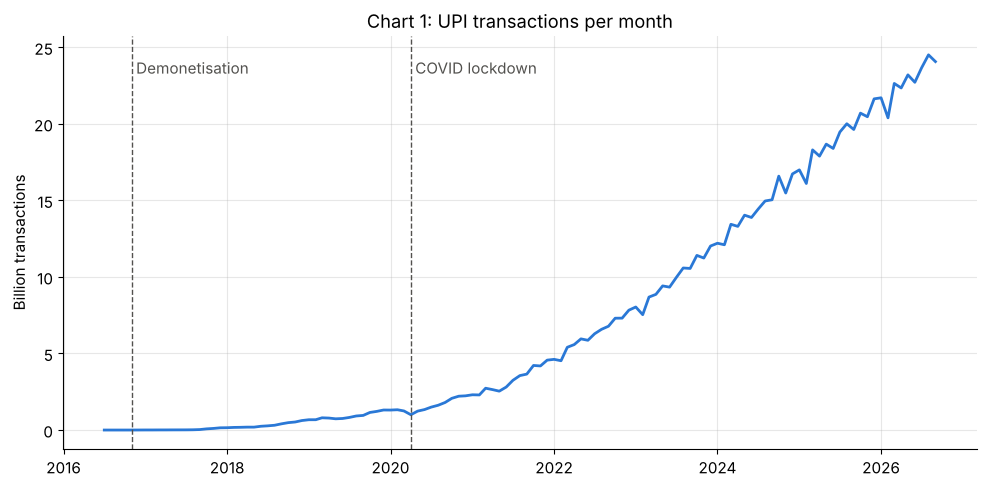

In [13]:
events = [('2016-11-01', 'Demonetisation'), ('2020-04-01', 'COVID lockdown')]

fig, ax = plt.subplots()
ax.plot(df['date'], df['volume_bn'], color=BLUE, lw=2)
for date, label in events:
    ax.axvline(pd.Timestamp(date), color=GREY, ls='--', lw=1)
    ax.text(pd.Timestamp(date), df['volume_bn'].max() * 0.95, ' ' + label, color=GREY)
ax.set_title('Chart 1: UPI transactions per month')
ax.set_ylabel('Billion transactions')
save('chart1-monthly-volume')

### 5.4 Chart 2: Volume vs value, on a log scale
Both series are **indexed to 100 in April 2019** so they share one axis. On a **log scale**, a straight line means a constant growth rate; a line that flattens means growth is slowing. The gap opening between the two lines is the ticket size shrinking.

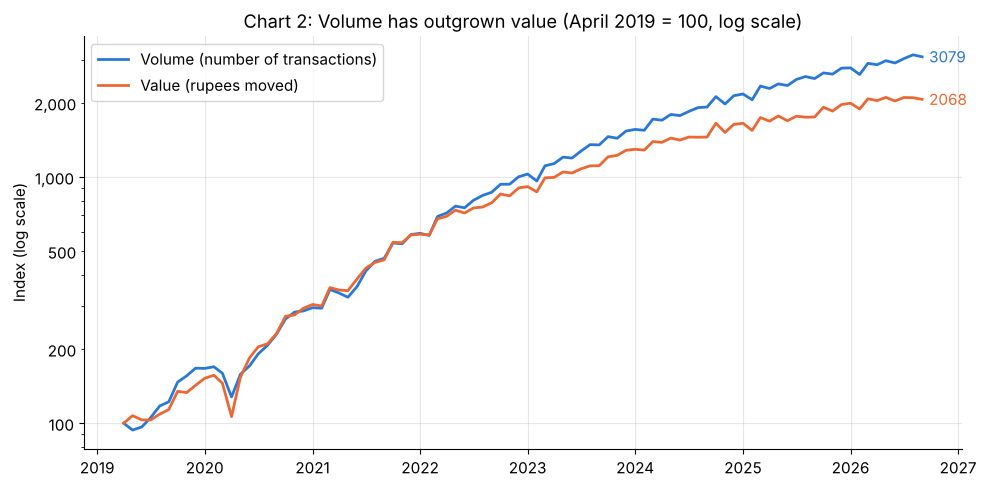

Since April 2019: volume x30.8, value x20.7


In [14]:
base = df[df['date'] >= '2019-04-01'].copy()
base['volume_index'] = base['volume_mn'] / base['volume_mn'].iloc[0] * 100
base['value_index'] = base['value_cr'] / base['value_cr'].iloc[0] * 100

fig, ax = plt.subplots()
ax.plot(base['date'], base['volume_index'], color=BLUE, lw=2, label='Volume (number of transactions)')
ax.plot(base['date'], base['value_index'], color=ORANGE, lw=2, label='Value (rupees moved)')
ax.set_yscale('log')
plain_numbers(ax)
ax.set_title('Chart 2: Volume has outgrown value (April 2019 = 100, log scale)')
ax.set_ylabel('Index (log scale)')
ax.legend()
for col, colour in [('volume_index', BLUE), ('value_index', ORANGE)]:
    last = base.iloc[-1]
    ax.annotate(f'{last[col]:.0f}', (last['date'], last[col]), xytext=(5, 0),
                textcoords='offset points', color=colour, va='center')
save('chart2-volume-vs-value-index')

print(f"Since April 2019: volume x{base['volume_index'].iloc[-1]/100:.1f}, value x{base['value_index'].iloc[-1]/100:.1f}")

### 5.5 Chart 3: Year-on-year growth is falling (RQ1)
Starts in April 2019: before that, YoY growth was in the hundreds or thousands of percent and would flatten everything else on the chart.

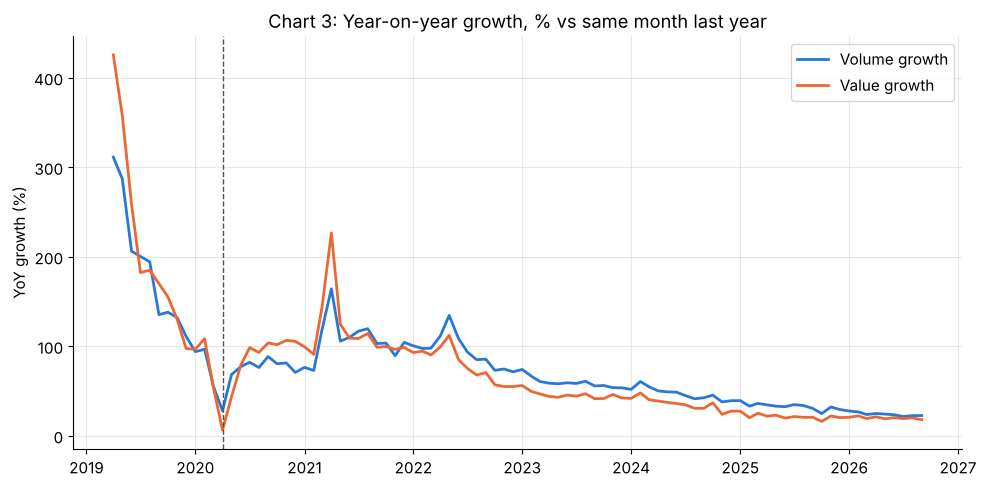

         month  yoy_volume  yoy_value
September-2019       135.3      169.8
September-2020        88.5      103.8
September-2021       103.0       98.9
September-2022        85.6       70.6
September-2023        55.7       41.4
September-2024        42.5       30.7
September-2025        30.5       20.6
September-2026        22.6       18.0


In [15]:
recent = df[df['date'] >= '2019-04-01']

fig, ax = plt.subplots()
ax.plot(recent['date'], recent['yoy_volume'], color=BLUE, lw=2, label='Volume growth')
ax.plot(recent['date'], recent['yoy_value'], color=ORANGE, lw=2, label='Value growth')
ax.axvline(pd.Timestamp('2020-04-01'), color=GREY, ls='--', lw=1)
ax.set_title('Chart 3: Year-on-year growth, % vs same month last year')
ax.set_ylabel('YoY growth (%)')
ax.legend()
save('chart3-yoy-growth')

print(recent[recent['month_num'] == 9][['month', 'yoy_volume', 'yoy_value']].round(1).to_string(index=False))

Note the spike in **April and May 2021**: that is not real acceleration. It compares against April and May 2020 (lockdown), a very low base. This is the *base effect*.

### 5.6 Chart 4: The average UPI payment is shrinking (RQ2)

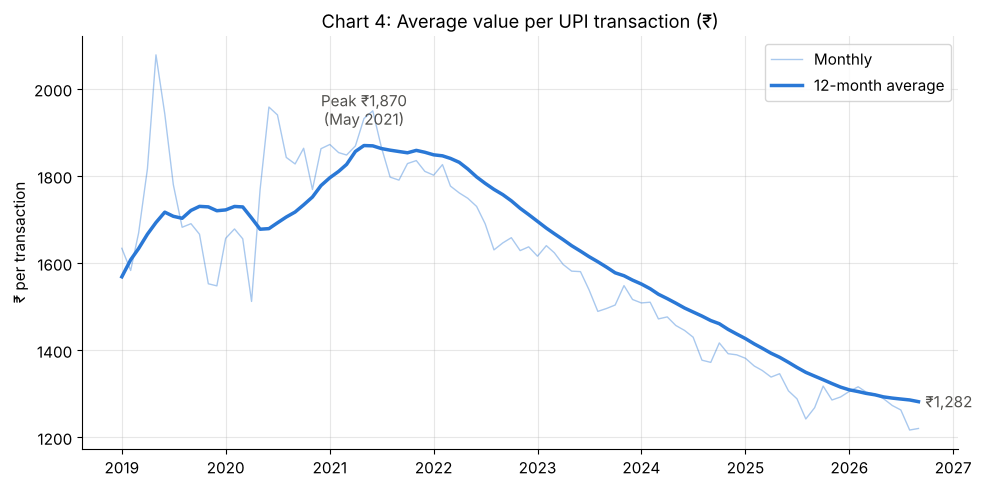

12-month average ticket: peak ₹1,870 (May 2021), now ₹1,282: -31%


In [16]:
# Start in 2019: in 2016-18 UPI had few users and a handful of large transfers dominated the average
tick = df[df['date'] >= '2019-01-01']

fig, ax = plt.subplots()
ax.plot(tick['date'], tick['ticket_rs'], color=BLUE, lw=1, alpha=0.4, label='Monthly')
ax.plot(tick['date'], tick['ticket_12m'], color=BLUE, lw=2.5, label='12-month average')

peak = tick.loc[tick['ticket_12m'].idxmax()]
ax.annotate(f"Peak ₹{peak['ticket_12m']:,.0f}\n({peak['date']:%b %Y})", (peak['date'], peak['ticket_12m']),
            xytext=(0, 15), textcoords='offset points', ha='center', color=GREY)
last = tick.iloc[-1]
ax.annotate(f"₹{last['ticket_12m']:,.0f}", (last['date'], last['ticket_12m']),
            xytext=(5, 0), textcoords='offset points', va='center', color=GREY)
ax.set_title('Chart 4: Average value per UPI transaction (₹)')
ax.set_ylabel('₹ per transaction')
ax.legend()
save('chart4-ticket-size')

change = (last['ticket_12m'] / peak['ticket_12m'] - 1) * 100
print(f"12-month average ticket: peak ₹{peak['ticket_12m']:,.0f} ({peak['date']:%b %Y}), now ₹{last['ticket_12m']:,.0f}: {change:.0f}%")

In [17]:
# Same story by calendar year
yearly = df.groupby('year')[['value_cr', 'volume_mn']].sum()
yearly['ticket_rs'] = yearly['value_cr'] * 1e7 / (yearly['volume_mn'] * 1e6)
yearly.loc[2018:, ['ticket_rs']].round(0).T

year,2018,2019,2020,2021,2022,2023,2024,2025,2026
ticket_rs,1563.0,1703.0,1794.0,1848.0,1701.0,1555.0,1433.0,1313.0,1275.0


### 5.7 Chart 5: Seasonality, and why per-day adjustment matters (RQ3)
For each month we measure how far it sits **above or below its own 12-month moving average** (the local trend), then average by calendar month. We do this twice: on raw monthly totals and on per-day volume.

If February looks weak only because it has fewer days, the per-day version should remove that dip.

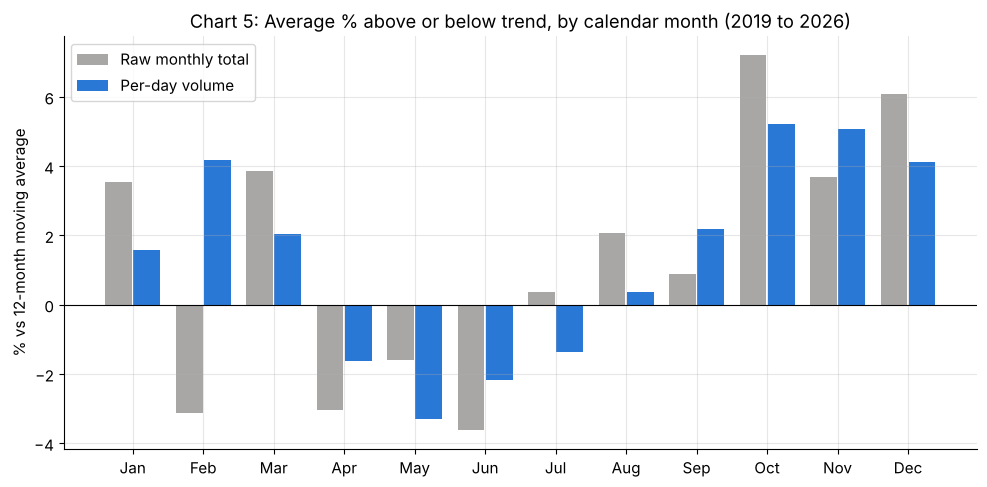

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
raw_vs_trend,3.5,-3.1,3.9,-3.0,-1.6,-3.6,0.4,2.1,0.9,7.2,3.7,6.1
daily_vs_trend,1.6,4.2,2.0,-1.6,-3.3,-2.2,-1.4,0.4,2.2,5.2,5.1,4.1


In [18]:
s = df[df['date'] >= '2019-04-01'].copy()
s['raw_vs_trend'] = (s['volume_mn'] / s['volume_mn'].rolling(12, center=True).mean() - 1) * 100
s['daily_vs_trend'] = (s['daily_volume_mn'] / s['daily_volume_mn'].rolling(12, center=True).mean() - 1) * 100

season = s.groupby('month_num')[['raw_vs_trend', 'daily_vs_trend']].mean()
season.index = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

x = np.arange(12)
fig, ax = plt.subplots()
ax.bar(x - 0.2, season['raw_vs_trend'], width=0.38, color=GREY, alpha=0.5, label='Raw monthly total')
ax.bar(x + 0.2, season['daily_vs_trend'], width=0.38, color=BLUE, label='Per-day volume')
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x)
ax.set_xticklabels(season.index)
ax.set_title('Chart 5: Average % above or below trend, by calendar month (2019 to 2026)')
ax.set_ylabel('% vs 12-month moving average')
ax.legend()
save('chart5-seasonality')

season.round(1).T

February flips from **below** trend (raw) to **above** trend (per day): its weakness was just the missing days. After adjusting, **October to December** stand out: the festive and wedding season (Navratri, Diwali, year-end shopping).

### 5.8 Chart 6: Do more banks mean more transactions? (RQ4)

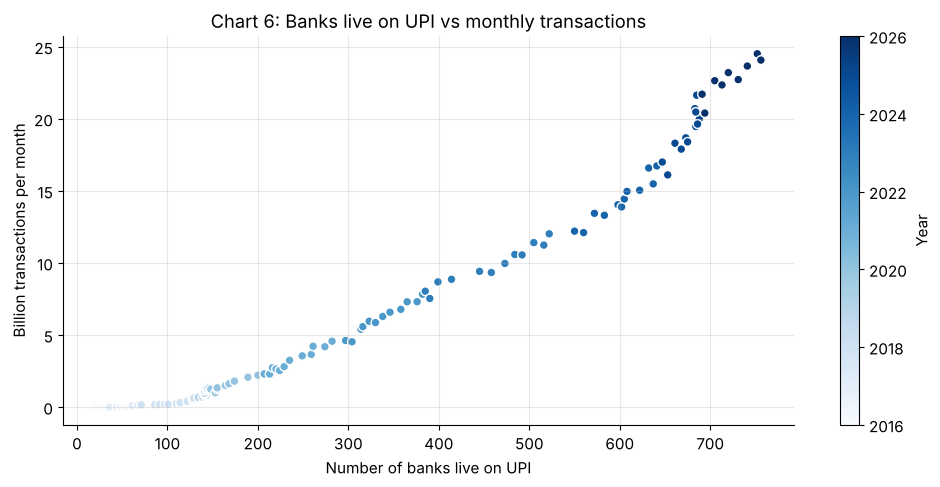

Correlation of levels (banks vs volume):        0.98
Correlation of YoY growth rates (since 2019):   0.42


In [19]:
fig, ax = plt.subplots()
sc = ax.scatter(df['banks_live'], df['volume_bn'], c=df['year'], cmap='Blues', s=40, edgecolor='white')
plt.colorbar(sc, label='Year')
ax.set_title('Chart 6: Banks live on UPI vs monthly transactions')
ax.set_xlabel('Number of banks live on UPI')
ax.set_ylabel('Billion transactions per month')
save('chart6-banks-vs-volume')

corr_levels = df[['banks_live', 'volume_mn']].corr().iloc[0, 1]
corr_growth = df[df['date'] >= '2019-04-01'][['yoy_banks', 'yoy_volume']].corr().iloc[0, 1]
print(f'Correlation of levels (banks vs volume):        {corr_levels:.2f}')
print(f'Correlation of YoY growth rates (since 2019):   {corr_growth:.2f}')

The level correlation (0.98) looks like proof that banks drive volume, but **both series simply rise over time**. Any two trending series correlate strongly; this is called a *spurious correlation*. Comparing **growth rates** removes the shared trend, and the correlation drops to about 0.4. Bank onboarding is part of the story, but far from all of it. This is why we do **not** regress volume on banks.

## 6. Regression: is growth really slowing?
### The model

$$\log(\text{daily volume}_t) = \beta_0 + \beta_1 t + \beta_2 t^2 + \sum_{m=2}^{12} \gamma_m \text{Month}_m + \delta\,\text{COVID}_t + \varepsilon_t$$

| Term | Meaning |
|---|---|
| `log(daily volume)` | Log turns growth into a straight line; coefficients read as % effects. Per-day removes the February effect. |
| `t` | Months since April 2019 (0, 1, 2, ...). β₁ = underlying growth rate. |
| `t²` | **The key term.** If β₂ < 0, the growth rate itself is falling over time. |
| `C(month_num)` | 11 month dummies (January is the baseline). Captures festive season etc. |
| `covid` | 1 for April and May 2020 (national lockdown), else 0 |

**Implied growth rate at any month:** the slope of the curve is β₁ + 2β₂t per month, so annual growth = e^(12 × (β₁ + 2β₂t)) − 1.

**Why Newey-West (HAC) standard errors?** In monthly data, this month's error is correlated with last month's (autocorrelation). Ordinary standard errors then look too small and coefficients look more significant than they are. `cov_type='HAC'` corrects for that. The coefficients stay the same; only the standard errors and p-values change.

**Why start in April 2019?** 2016 to 2018 was the launch phase (banks onboarding, demonetisation, BHIM app launch) with growth of 300% to 1000%+. A smooth curve cannot fit both that phase and the mature phase. The robustness check below shows the conclusion holds for other start dates.

In [20]:
reg = df[df['date'] >= '2019-04-01'].copy()
reg['t'] = np.arange(len(reg))
reg['covid'] = reg['date'].between('2020-04-01', '2020-05-01').astype(int)

model = smf.ols('np.log(daily_volume_mn) ~ t + I(t**2) + C(month_num) + covid', data=reg)
results = model.fit(cov_type='HAC', cov_kwds={'maxlags': 12})
print(results.summary())

                               OLS Regression Results                              
Dep. Variable:     np.log(daily_volume_mn)   R-squared:                       0.997
Model:                                 OLS   Adj. R-squared:                  0.997
Method:                      Least Squares   F-statistic:                     3987.
Date:                     Mon, 26 Oct 2026   Prob (F-statistic):          1.27e-101
Time:                             18:13:39   Log-Likelihood:                 131.74
No. Observations:                       90   AIC:                            -233.5
Df Residuals:                           75   BIC:                            -196.0
Df Model:                               14                                         
Covariance Type:                       HAC                                         
                         coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------

### Interpreting the results

In [21]:
b = results.params
p = results.pvalues

print(f"Observations: {int(results.nobs)}   R-squared: {results.rsquared:.3f}")
print(f"Durbin-Watson: {durbin_watson(results.resid):.2f}  (2 = no autocorrelation; well below 2 = strong autocorrelation, so HAC is needed)")
print()
print(f"t-squared coefficient: {b['I(t ** 2)']:.6f}  (p = {p['I(t ** 2)']:.4f})")
print('  -> negative and significant: the growth rate is falling over time')
print(f"COVID lockdown effect: {(np.exp(b['covid']) - 1) * 100:.1f}% below trend  (p = {p['covid']:.4f})")
print()
for label, t in [('April 2019', 0), ('April 2021', 24), ('April 2023', 48), ('April 2025', 72), ('September 2026', reg['t'].max())]:
    monthly_slope = b['t'] + 2 * b['I(t ** 2)'] * t
    print(f"Implied annual growth, {label:>14}: {(np.exp(12 * monthly_slope) - 1) * 100:5.0f}%")

Observations: 90   R-squared: 0.997
Durbin-Watson: 0.70  (2 = no autocorrelation; well below 2 = strong autocorrelation, so HAC is needed)

t-squared coefficient: -0.000315  (p = 0.0000)
  -> negative and significant: the growth rate is falling over time
COVID lockdown effect: -26.7% below trend  (p = 0.0000)

Implied annual growth,     April 2019:   127%
Implied annual growth,     April 2021:    90%
Implied annual growth,     April 2023:    58%
Implied annual growth,     April 2025:    32%
Implied annual growth, September 2026:    16%


In [22]:
# How much did the HAC correction matter? Same model with ordinary standard errors
plain = model.fit()
print(f"Std. error of t-squared, ordinary OLS: {plain.bse['I(t ** 2)']:.2e}")
print(f"Std. error of t-squared, Newey-West:   {results.bse['I(t ** 2)']:.2e}")
print(f"Newey-West standard error is {results.bse['I(t ** 2)'] / plain.bse['I(t ** 2)']:.1f}x larger")

Std. error of t-squared, ordinary OLS: 1.09e-05
Std. error of t-squared, Newey-West:   1.94e-05
Newey-West standard error is 1.8x larger


In [23]:
# Seasonal effects: % difference from January, after removing trend and COVID
month_names = ['Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
month_effects = pd.DataFrame({
    'effect_vs_January_%': ((np.exp(b.filter(like='C(month_num)')) - 1) * 100).values,
    'p_value': p.filter(like='C(month_num)').values}, index=month_names)
month_effects['significant_at_5%'] = month_effects['p_value'] < 0.05
month_effects.round(3)

,effect_vs_January_%,p_value,significant_at_5%
Feb,2.410,0.001,True
Mar,0.292,0.909,False
Apr,2.741,0.280,False
May,-0.155,0.950,False
Jun,-3.112,0.251,False
Jul,-2.739,0.238,False
Aug,-0.714,0.731,False
Sep,0.750,0.598,False
Oct,4.438,0.001,True
Nov,3.833,0.026,True


### Chart 7: Model fit

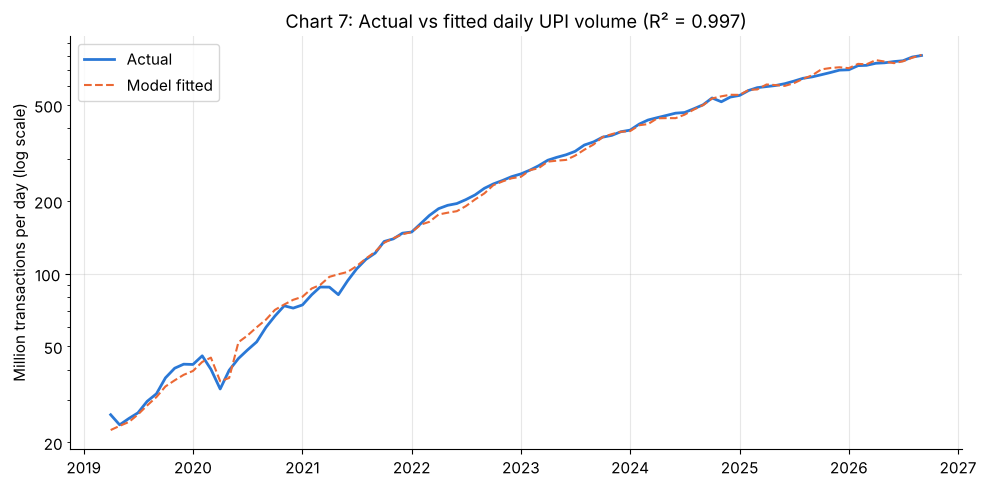

In [24]:
fig, ax = plt.subplots()
ax.plot(reg['date'], reg['daily_volume_mn'], color=BLUE, lw=2, label='Actual')
ax.plot(reg['date'], np.exp(results.fittedvalues), color=ORANGE, lw=1.5, ls='--', label='Model fitted')
ax.set_yscale('log')
plain_numbers(ax)
ax.set_title(f'Chart 7: Actual vs fitted daily UPI volume (R² = {results.rsquared:.3f})')
ax.set_ylabel('Million transactions per day (log scale)')
ax.legend()
save('chart7-actual-vs-fitted')

### Chart 8: The growth curve is bending (RQ1 answer)
Implied annual growth from the model (line) against actual year-on-year growth (dots).

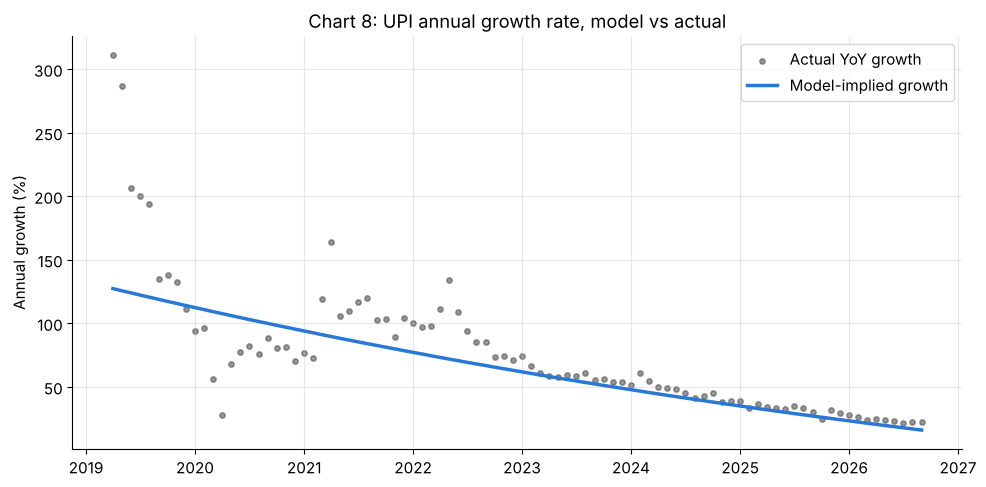

In [25]:
reg['implied_growth'] = (np.exp(12 * (b['t'] + 2 * b['I(t ** 2)'] * reg['t'])) - 1) * 100

fig, ax = plt.subplots()
ax.scatter(reg['date'], reg['yoy_volume'], color=GREY, s=15, alpha=0.6, label='Actual YoY growth')
ax.plot(reg['date'], reg['implied_growth'], color=BLUE, lw=2.5, label='Model-implied growth')
ax.set_title('Chart 8: UPI annual growth rate, model vs actual')
ax.set_ylabel('Annual growth (%)')
ax.legend()
save('chart8-implied-growth')

### Chart 9: Residual check
Residuals should be centred on zero with no obvious pattern. Two things stand out:
- **Waves** (runs of positive or negative months): this is the autocorrelation that Newey-West corrects for.
- **The deep dip around April to May 2021**: the second COVID wave and state lockdowns, which the COVID dummy (2020 only) does not cover. After 2022 the residuals are small and stable.

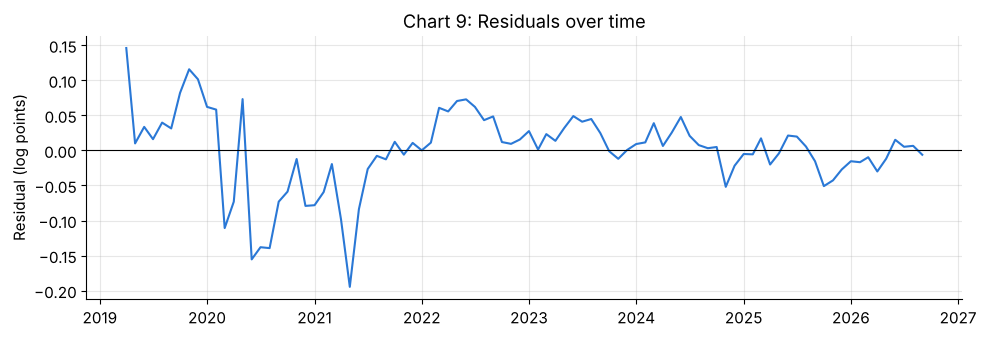

In [26]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(reg['date'], results.resid, color=BLUE, lw=1.5)
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Chart 9: Residuals over time')
ax.set_ylabel('Residual (log points)')
save('chart9-residuals')

### Robustness check: does the start date change the conclusion?

In [27]:
rows = []
for start in ['2017-04-01', '2018-04-01', '2019-04-01', '2020-04-01']:
    r = df[df['date'] >= start].copy()
    r['t'] = np.arange(len(r))
    r['covid'] = r['date'].between('2020-04-01', '2020-05-01').astype(int)
    formula = 'np.log(daily_volume_mn) ~ t + I(t**2) + C(month_num)' + (' + covid' if r['covid'].sum() > 0 else '')
    res = smf.ols(formula, data=r).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
    rows.append({'sample_start': start[:7], 'months': int(res.nobs),
                 't2_coefficient': res.params['I(t ** 2)'], 'p_value': res.pvalues['I(t ** 2)'],
                 'R_squared': res.rsquared})

pd.DataFrame(rows).round(5)

,sample_start,months,t2_coefficient,p_value,R_squared
0,2017-04,114,-0.00059,0.0,0.96247
1,2018-04,102,-0.00034,0.0,0.99534
2,2019-04,90,-0.00031,0.0,0.99731
3,2020-04,78,-0.00039,0.0,0.99842


The t² coefficient is **negative and significant in every sample**. The slowdown is not an artefact of the chosen start date.

## 7. Key findings

1. **Growth is decelerating, and the regression confirms it.** UPI volume growth fell from about 135% YoY (Sep 2019) to about 23% (Sep 2026). The t² term is negative and significant (p < 0.001 with Newey-West errors), and holds for every sample start date. Model-implied annual growth falls from about 127% (2019) to about 16% (2026): a classic S-curve of adoption.

2. **UPI is growing in count, not in money.** Since April 2019 volume has grown about 31x but value only about 21x. The 12-month average ticket size has fallen from a peak of about ₹1,870 (May 2021) to about ₹1,280 (Sep 2026), 31% smaller. UPI is increasingly used for small everyday payments (tea, auto, groceries), not just bigger transfers.

3. **Raw monthly totals mislead.** February looks about 3% below trend on raw totals but is about 4% *above* trend per day. After adjusting, **October to December** are significantly above January (festive and wedding season); the regression confirms Oct (+4.4%), Nov (+3.8%) and Dec (+2.7%) at the 5% level.

4. **The COVID lockdown cut UPI volume by about 27% below trend** in April and May 2020, followed by a fast recovery. It accelerated adoption rather than stalling it.

5. **"More banks = more UPI" is mostly a shared trend.** Banks and volume correlate at 0.98 in levels, but only about 0.4 in growth rates. Bank onboarding helps, but adoption is driven by more than network size.

*Exact figures are printed in the cells above.*

## 8. Limitations
- **Aggregate data only.** NPCI's monthly series has no split by person-to-person vs person-to-merchant, state, or app. The "small everyday payments" explanation is consistent with the data but not directly tested.
- **Ticket size is an average.** A few very large transactions can move it; the median payment is not published.
- **The quadratic trend is descriptive, not a forecast.** Extended far enough, a negative t² predicts falling volume, which is not a sensible prediction. It measures the slowdown within the sample only.
- **COVID dummy covers only the first lockdown (April and May 2020).** The second wave (April and May 2021) shows up as large negative residuals; a second dummy would improve the fit.
- **Correlation, not causation**, for the banks analysis.

**Future scope:** add NPCI's P2P/P2M split and app-wise market share data; fit a proper S-curve (logistic) model; compare with RBI data on cash in circulation.